# 01 · EDA des données StatsBomb pour l'expected threat (xT)

L'objectif de ce notebook est de comprendre ce que les données ouvertes de StatsBomb offrent
réellement, de justifier nos choix de données et de nettoyage, et de produire les figures du
rapport (enregistrées dans `figures/`). Il lit les tables construites par `00_fetch_dataset.ipynb`
(à exécuter d'abord).

Ce dont xT a besoin, pour chaque case $z$ d'une grille du terrain (Singh, 2019) :

$$xT(z) = s_z \, g_z + m_z \sum_{z'} T_{z \to z'} \, xT(z')$$

* $s_z, m_z$ : probabilité de tirer / de bouger le ballon depuis $z$,
* $g_z$ : probabilité de marquer sur un tir depuis $z$ (≈ xG),
* $T_{z \to z'}$ : probabilité qu'un mouvement (passe, conduite, dribble) réussi aille de $z$ à $z'$.



In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xt.data import load_competitions, load_matches, load_actions, PITCH_X, PITCH_Y
from xt.data.fetch import REPO_ROOT
from xt.features import (add_cells, count_grid, move_cells, action_probabilities,
                         transition_counts, possession_table)
from xt.evaluation import make_split, save_split, eda_matches, log_loss, brier, calibration_table
from xt.visualizations import grid_heatmap

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
NX, NY = 16, 12  # grille de Singh (2019) : 192 cases de 7.5 x 6.67 unités StatsBomb

FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## Split tout de suite, par soucis de leakage

Pour éviter le *data snooping* (choisir le modèle en regardant les données qui serviront à le
tester, ce qui rend le test trop optimiste), on va vite fixer le découpage suivant avant toute analyse (le code est dans
`data/processed/split.csv`):

| Jeu | Matchs | Rôle |
|---|---|---|
| `train` | 70 % de chaque championnat 2015/16 | entraînement |
| `val` | 15 % de chaque championnat 2015/16 | choix des hyperparamètres et des priors |
| `recent_val` | Coupe du monde 2022 | voir si ça généralise bien au football plus récent |
| `test` | 15 % de chaque championnat 2015/16 | évaluation finale seulement |
| `recent_test` | Euro 2024 | évaluation finale de la généralisation vers le récent |

Ce notebook (et tout le développement des modèles) ne charge que `train`, `val` et `recent_val`.
Les deux autres qu'à la fin, quand tous les choix sont figés.
On les utilise dans ce notebook que pour voir le nombre de matchs. 

In [2]:
# Mêmes paires que dans 00_fetch.ipynb (à exécuter d'abord avec ces paires, sinon load_actions
# télécharge et construit les tables manquantes : ~4 Go de JSON pour les 4 championnats).
# 4 championnats complets 2015/16 : Premier League, Liga, Serie A, Ligue 1
PAIRS_TRAIN = [(2, 27), (11, 27), (12, 27), (7, 27)]
# Récent pour l'exploration et la validation : Coupe du monde 2022 (avec 360)
PAIRS_RECENT = [(43, 106)]
# Test final récent : Euro 2024. Ses événements ne sont pas chargés dans ce notebook.
PAIRS_LOCKED = [(55, 282)]
PAIRS = PAIRS_TRAIN + PAIRS_RECENT

# Découpage par match, construit à partir des seules métadonnées des matchs (aucun événement lu)
split = make_split(PAIRS_TRAIN, recent_val_pairs=PAIRS_RECENT, recent_test_pairs=PAIRS_LOCKED)
save_split(split)
ALLOWED = eda_matches(split)   # train + val (2015/16) + recent_val (CM 2022)

actions = load_actions(PAIRS, progress=False).drop(columns="event_id")
actions = actions[actions.match_id.isin(ALLOWED)].reset_index(drop=True)   # le test 2015/16 est retiré
# ~3,3 M lignes : les colonnes texte répétitives qui ne servent pas à grouper passent en `category`
# (divise la mémoire par ~2 ; `competition_name`, `type` et `sub_type` restent du texte pour que les
# groupby ne fassent pas apparaître de catégories vides)
for col in ["player", "position", "play_pattern", "body_part",
            "pass_height", "outcome", "shot_technique", "season_name"]:
    actions[col] = actions[col].astype("category")
actions = add_cells(actions, NX, NY)
RECENT = {"FIFA World Cup"}
actions["era"] = np.where(actions.competition_name.isin(RECENT), "World Cup 2022", "2015/16 leagues")
print(f"{actions.match_id.nunique()} matchs, {len(actions):,} actions, {actions.memory_usage(deep=True).sum() / 1e9:.1f} Go en mémoire")
actions.groupby(["era", "competition_name", "season_name"], observed=True).match_id.nunique()

1353 matchs, 2,764,887 actions, 0.9 Go en mémoire


era              competition_name  season_name
2015/16 leagues  La Liga           2015/2016      323
                 Ligue 1           2015/2016      320
                 Premier League    2015/2016      323
                 Serie A           2015/2016      323
World Cup 2022   FIFA World Cup    2022            64
Name: match_id, dtype: int64

## 1. Quelles compétitions utiliser ?

StatsBomb publie une sélection de compétitions, souvent partielles. Pour estimer un xT il faut
beaucoup d'actions et un échantillon représentatif de toutes les équipes. Pour chaque
compétition-saison, on regarde le nombre de matchs, le nombre d'équipes, et la part des matchs
joués par l'équipe la plus présente (parce qu'elle est parfois proche de 100 %, parce qu'enfait certains échantillons couvrent en
réalité qu'une seule équipe pour une saison)

In [3]:
comps = load_competitions()
rows = []
for r in comps.itertuples():
    m = load_matches(r.competition_id, r.season_id)
    teams = pd.concat([m.home_team, m.away_team])
    rows.append({"competition_id": r.competition_id, "season_id": r.season_id,
                 "competition": r.competition_name, "season": r.season_name,
                 "gender": r.competition_gender, "n_matches": len(m), "n_teams": teams.nunique(),
                 "top_team_share": teams.value_counts().iloc[0] / len(m),
                 "has_360": isinstance(r.match_available_360, str)})
coverage = pd.DataFrame(rows).sort_values("n_matches", ascending=False).reset_index(drop=True)
print(f"{len(coverage)} compétitions-saisons, {coverage.n_matches.sum():,} matchs au total")
coverage.head(20).round(2)

80 compétitions-saisons, 3,961 matchs au total


,competition_id,season_id,competition,season,gender,n_matches,n_teams,top_team_share,has_360
0,2,27,Premier League,2015/2016,male,380,20,0.10,False
1,12,27,Serie A,2015/2016,male,380,20,0.10,False
2,11,27,La Liga,2015/2016,male,380,20,0.10,False
3,7,27,Ligue 1,2015/2016,male,377,20,0.10,False
4,182,281,Liga F,2023/2024,female,240,16,0.12,False
5,49,107,NWSL,2023,female,137,12,0.18,False
6,37,281,FA Women's Super League,2023/2024,female,132,12,0.17,False
7,135,281,Frauen Bundesliga,2023/2024,female,132,12,0.17,False
8,37,90,FA Women's Super League,2020/2021,female,131,12,0.17,False
9,131,281,Serie A Women,2023/2024,female,130,10,0.20,False


In [4]:
# Saisons centrées sur une seule équipe : au moins 10 matchs, et l'équipe la plus présente en joue >= 90 %
# (les tournois avec 1-3 matchs, souvent juste la finale, ne sont pas comptés ici)
single = coverage[(coverage.n_matches >= 10) & (coverage.top_team_share >= 0.9)]
print(f"{len(single)} compétitions-saisons ({single.n_matches.sum()} matchs) ne couvrent qu'une équipe :")
single_team = {(r.competition_id, r.season_id): pd.concat([load_matches(r.competition_id, r.season_id)[c] for c in ["home_team", "away_team"]]).mode()[0]
               for r in single.itertuples()}
single.assign(team=[single_team[(r.competition_id, r.season_id)] for r in single.itertuples()])     [["competition", "season", "n_matches", "team"]].sort_values(["competition", "season"])

20 compétitions-saisons (643 matchs) ne couvrent qu'une équipe :


,competition,season,n_matches,team
29,1. Bundesliga,2015/2016,34,Bayer Leverkusen
28,1. Bundesliga,2023/2024,34,Bayer Leverkusen
43,La Liga,2005/2006,17,Barcelona
42,La Liga,2006/2007,26,Barcelona
40,La Liga,2007/2008,27,Barcelona
37,La Liga,2008/2009,31,Barcelona
25,La Liga,2009/2010,35,Barcelona
32,La Liga,2010/2011,33,Barcelona
22,La Liga,2011/2012,37,Barcelona
33,La Liga,2012/2013,32,Barcelona


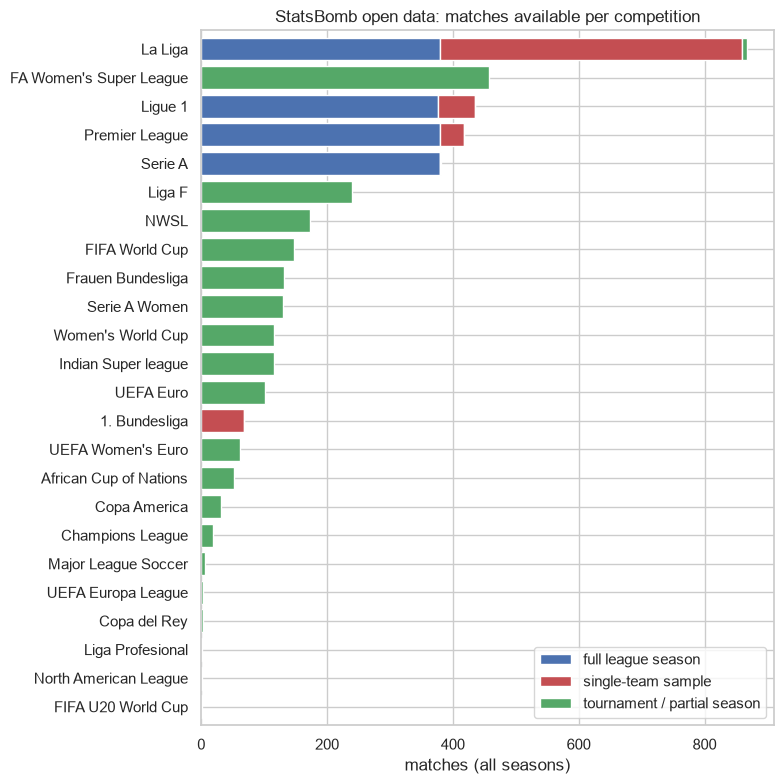

In [5]:
cov = coverage.assign(kind=np.select(
    [(coverage.n_matches >= 10) & (coverage.top_team_share >= 0.9), coverage.n_matches >= 300],
    ["single-team sample", "full league season"], "tournament / partial season"))
by_comp = (cov.groupby(["competition", "kind"], as_index=False).n_matches.sum()
           .pivot(index="competition", columns="kind", values="n_matches").fillna(0))
by_comp = by_comp.loc[by_comp.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 8))
by_comp.plot.barh(stacked=True, ax=ax, color={"full league season": "C0", "tournament / partial season": "C2",
                                               "single-team sample": "C3"}, width=0.8)
ax.set_xlabel("matches (all seasons)"); ax.set_ylabel("")
ax.set_title("StatsBomb open data: matches available per competition")
ax.legend(title=None, loc="lower right")
plt.tight_layout(); save(fig, "eda_coverage")

**Choix des données.**
* **Premier League, Liga, Serie A et Ligue 1 2015/16** sont les seules saisons masculines
  complètes (≈ 380 matchs chacune, ~1 500 au total, 20 équipes) : c'est le jeu d'entraînement le
  plus adapté à un xT « classique » dense. 
* Les tournois récents (Coupe du monde 2022, Euro 2020/2024…) sont courts mais ont les données
  360 (positions des joueurs visibles ce qui serait utile pour une
  éventuelle variante type DxT). Nous les utiliserons pour valider et tester le modèle. 

## 2. Table d'actions et choix de nettoyage

`xt.data.build_actions` garde, pour chaque match, les événements utiles à xT : les **mouvements**
(passes, conduites/*carries*, dribbles), les **tirs**, et les événements de perte ou récupération
du ballon (dispossessed, miscontrol, interception, etc.). Toutes les équipes attaquent de gauche à
droite dans le repère StatsBomb (120 × 80, x = 120 = but adverse) donc pas besoin de retourner les
coordonnées.

In [6]:
counts = actions.groupby(["competition_name", "type"]).size().unstack(0).fillna(0).astype(int)
n_matches = actions.groupby("competition_name").match_id.nunique()
for comp in n_matches.index:
    counts[f"per match ({comp})"] = (counts[comp] / n_matches[comp]).round(1)
counts.sort_values(counts.columns[0], ascending=False)

competition_name,FIFA World Cup,La Liga,Ligue 1,Premier League,Serie A,per match (FIFA World Cup),per match (La Liga),per match (Ligue 1),per match (Premier League),per match (Serie A)
type,,,,,,,,,,
Pass,68515,310854,318209,312959,316127,1070.5,962.4,994.4,968.9,978.7
Carry,53764,235475,240322,234653,237830,840.1,729.0,751.0,726.5,736.3
Ball Recovery,5821,32830,35705,34812,35248,91.0,101.6,111.6,107.8,109.1
Clearance,2684,13810,14823,18460,15196,41.9,42.8,46.3,57.2,47.0
Dribble,1793,12429,10477,11582,9922,28.0,38.5,32.7,35.9,30.7
Miscontrol,1755,8934,10441,9160,9527,27.4,27.7,32.6,28.4,29.5
Foul Won,1693,9806,8924,7768,10347,26.5,30.4,27.9,24.0,32.0
Shot,1453,7760,7395,8442,8549,22.7,24.0,23.1,26.1,26.5
Dispossessed,1431,8022,9213,8930,7883,22.4,24.8,28.8,27.6,24.4


Choix de nettoyage (dans `clean.py`) et leur justification :

| Choix | Pourquoi |
|---|---|
| Retirer les tirs au buts (période 5) | biaiserait $g_z$ (penalty à 11 m sans défense) |
| Retirer les événements sans position | inutilisables sur la grille |
| Ramener les coordonnées dans 120 × 80 | quelques événements à 120.1 / 80.1 tomberaient hors grille |
| Passes `Unknown` / `Injury Clearance` → `ambiguous_outcome` | ce ne sont pas de vraies pertes de balle : à exclure du taux de réussite |
| Conduite ratée si suivie d'un `Dispossessed` / `Miscontrol` du même joueur | StatsBomb ne donne pas de résultat aux conduites |
| Garder les penalties en jeu (prolongation incluse) mais avec `sub_type = "Penalty"` | probabilité de but très différente : à modéliser à part |
| Garder les coups de pied arrêtés avec `set_piece = True` | le xT classique se calcule souvent en jeu ouvert seulement : on pourra filtrer |

In [7]:
moves = actions[actions.type.isin(["Pass", "Carry", "Dribble"])]
shots = actions[actions.type.eq("Shot")]
m_all = pd.concat([load_matches(c, s) for c, s in PAIRS])
m_all = m_all[m_all.match_id.isin(actions.match_id)]   # mêmes matchs que la table d'actions
real_goals = int((m_all.home_score + m_all.away_score).sum())

checks = pd.Series({
    "actions (après nettoyage)": len(actions),
    "passes au résultat ambigu (Unknown, Injury Clearance)": int(actions.ambiguous_outcome.sum()),
    "dribbles (pas de position d'arrivée, normal)": int(moves.type.eq("Dribble").sum()),
    "passes / conduites sans arrivée": int(moves[moves.type.isin(["Pass", "Carry"])].end_x.isna().sum()),
    "conduites de longueur nulle": int((moves.type.eq("Carry") & (moves.x == moves.end_x) & (moves.y == moves.end_y)).sum()),
    "actions de coup de pied arrêté": int(actions.set_piece.sum()),
    "penalties (hors tirs au but)": int(shots.sub_type.eq("Penalty").sum()),
    "actions en prolongation (périodes 3-4)": int(actions.period.isin([3, 4]).sum()),
    "tirs sans xG StatsBomb": int(shots.shot_xg.isna().sum()),
    "buts sur tir": int(shots.is_goal.sum()),
    "buts au score final": real_goals,
    "→ buts contre son camp (pas des tirs)": real_goals - int(shots.is_goal.sum()),
}, name="valeur").to_frame()
checks

,valeur
actions (après nettoyage),2764887
"passes au résultat ambigu (Unknown, Injury Clearance)",10707
"dribbles (pas de position d'arrivée, normal)",46203
passes / conduites sans arrivée,0
conduites de longueur nulle,118526
actions de coup de pied arrêté,146760
penalties (hors tirs au but),358
actions en prolongation (périodes 3-4),3265
tirs sans xG StatsBomb,0
buts sur tir,3423


Les conduites de longueur nulle (≈ 5 % des conduites) sont des réceptions immédiatement suivies
d'une passe : elles restent dans la même case, donc n'affectent que la diagonale de $T$. Les
buts contre son camp (≈ 4 % des buts) ne sont pas des tirs : $g_z$ ne les compte pas, ce qui est
voulu.

## 3. Où se passent les actions 

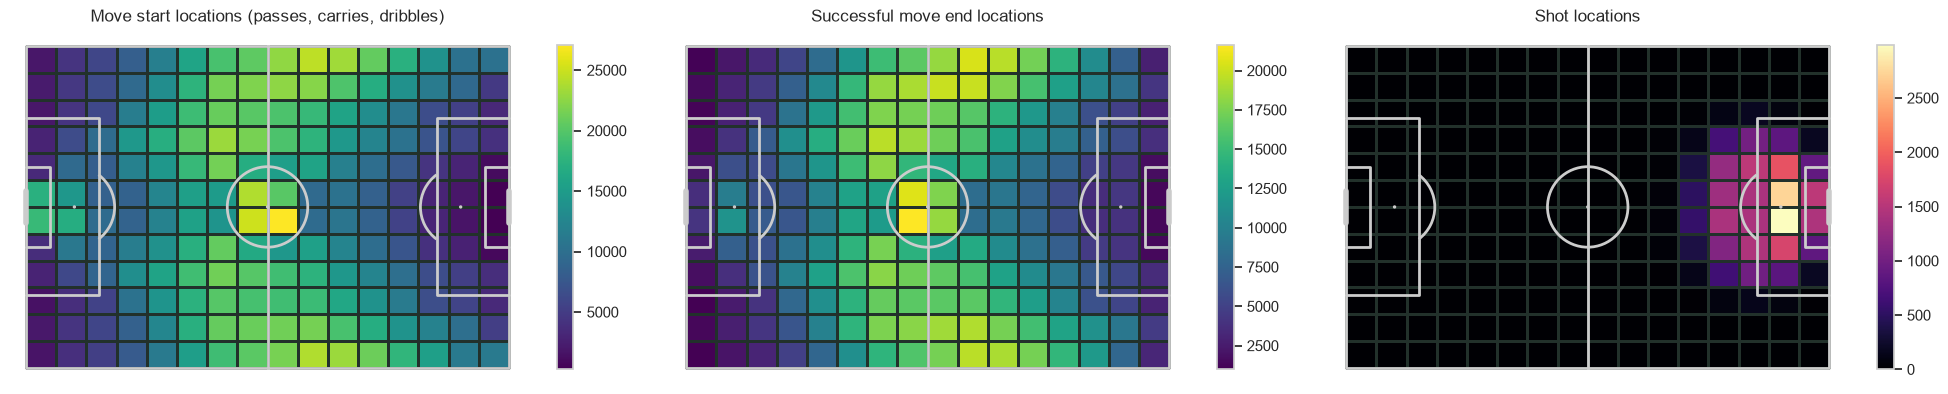

In [8]:
ok = moves[moves.success.eq(True) & moves.end_x.notna()]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
grid_heatmap(count_grid(moves.x, moves.y, NX, NY), ax=axes[0], title="Move start locations (passes, carries, dribbles)")
grid_heatmap(count_grid(ok.end_x, ok.end_y, NX, NY), ax=axes[1], title="Successful move end locations")
grid_heatmap(count_grid(shots.x, shots.y, NX, NY), ax=axes[2], title="Shot locations", cmap="magma")
plt.tight_layout(); save(fig, "eda_locations")

Les mouvements couvrent tout le terrain (sauf la surface adverse, peu fréquentée), alors que les
tirs sont concentrés dans ~20 cases devant le but. Le pic au rond central vient des coups d'envoi.

## 4. Réussite des mouvements ($m_z$ et $T$)

* **passe** réussie : pas d'`outcome` (StatsBomb n'en met un que si la passe échoue) ;
* **dribble** réussi : outcome `Complete` ;
* **conduite** réussie : sauf si suivie d'un `Dispossessed` / `Miscontrol` du même joueur.

In [9]:
clean_moves = moves[~moves.ambiguous_outcome]
rate = (clean_moves.groupby(["competition_name", "type"]).success
        .agg(["size", "mean"]).rename(columns={"size": "n", "mean": "success_rate"}).round(3))
rate

n  success_rate
competition_name type                         
FIFA World Cup   Carry     53764         0.949
                 Dribble    1793         0.523
                 Pass      68079         0.828
La Liga          Carry    235475         0.938
                 Dribble   12429          0.55
                 Pass     308272         0.764
Ligue 1          Carry    240322          0.93
                 Dribble   10477         0.531
                 Pass     315503         0.775
Premier League   Carry    234653         0.933
                 Dribble   11582         0.586
                 Pass     310999          0.77
Serie A          Carry    237830         0.938
                 Dribble    9922         0.546
                 Pass     313104          0.78

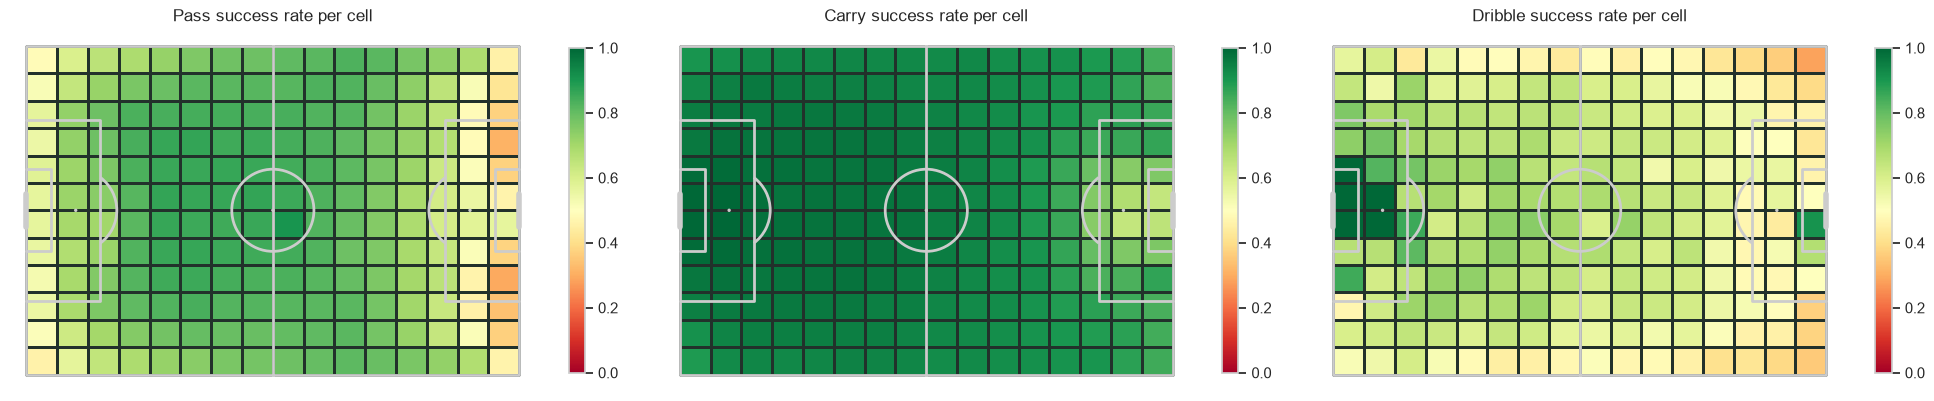

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, t in zip(axes, ["Pass", "Carry", "Dribble"]):
    d = clean_moves[clean_moves.type.eq(t)]
    n = count_grid(d.x, d.y, NX, NY)
    s = count_grid(d.x, d.y, NX, NY, weights=d.success.astype(float))
    with np.errstate(invalid="ignore", divide="ignore"):
        grid_heatmap(np.where(n > 0, s / n, np.nan), ax=ax, title=f"{t} success rate per cell",
                     cmap="RdYlGn", vmin=0, vmax=1)
plt.tight_layout(); save(fig, "eda_move_success")

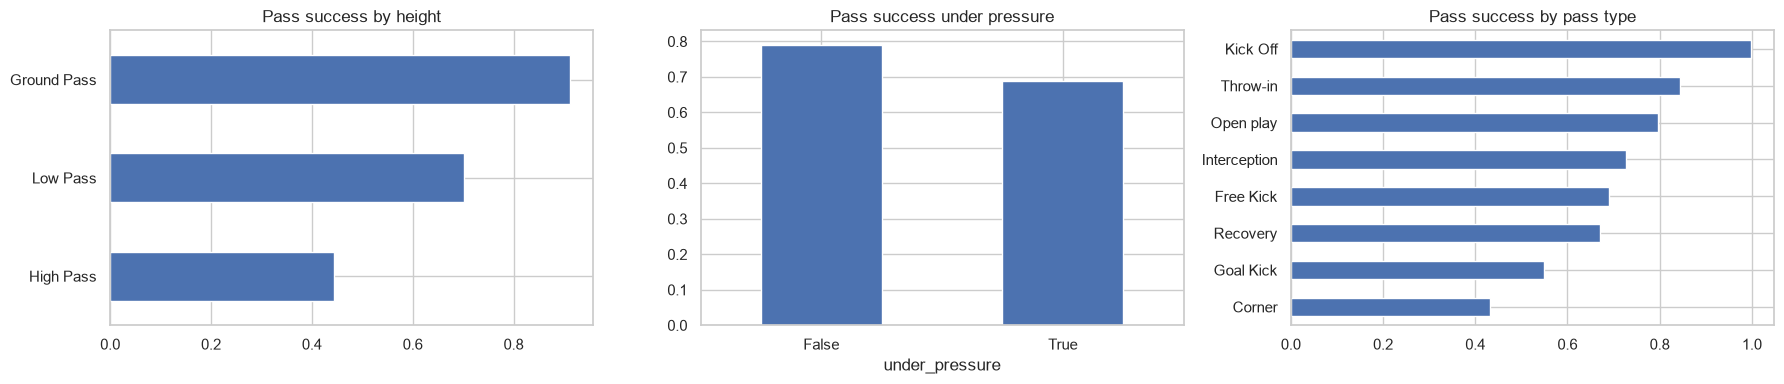

In [11]:
p = clean_moves[clean_moves.type.eq("Pass")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
p.groupby("pass_height").success.mean().sort_values().plot.barh(ax=axes[0], title="Pass success by height")
p.groupby("under_pressure").success.mean().plot.bar(ax=axes[1], title="Pass success under pressure", rot=0)
p.assign(sub_type=p.sub_type.fillna("Open play")).groupby("sub_type").success.mean().sort_values() \
    .plot.barh(ax=axes[2], title="Pass success by pass type")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); save(fig, "eda_pass_success_factors")

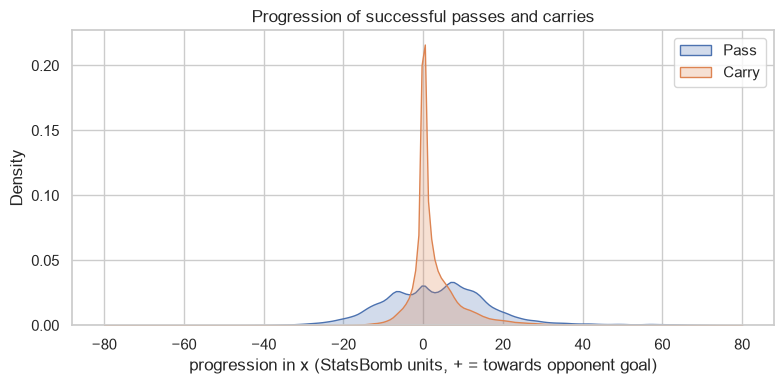

In [12]:
dx = ok.assign(dx=lambda d: d.end_x - d.x)
fig, ax = plt.subplots(figsize=(8, 4))
for t in ["Pass", "Carry"]:
    sns.kdeplot(dx.loc[dx.type.eq(t), "dx"], ax=ax, label=t, fill=True, bw_adjust=0.8, clip=(-80, 80))
ax.set_xlabel("progression in x (StatsBomb units, + = towards opponent goal)")
ax.legend(); ax.set_title("Progression of successful passes and carries")
plt.tight_layout(); save(fig, "eda_progression")

La réussite varie fortement selon la zone (passes dans le dernier tiers bien moins réussies), la
hauteur de passe et la pression, et les passes progressent beaucoup plus loin que les conduites.
C'est l'argument pour un **modèle de transition par type d'action** plutôt que la moyenne unique
du xT classique.

## 5. Tirs et buts ($s_z$ et $g_z$)

On compare le taux de but empirique au xG de StatsBomb (baseline à battre si on améliore le xG).
Les penalties sont retirés ici (probabilité de but ≈ 0.78, sans rapport avec la position).

In [13]:
summary = shots.groupby("competition_name").agg(shots=("is_goal", "size"), goals=("is_goal", "sum"),
                                                 xg_statsbomb=("shot_xg", "sum"),
                                                 penalties=("sub_type", lambda s: (s == "Penalty").sum()))
summary["shots_per_match"] = (summary.shots / n_matches).round(1)
summary["conversion"] = summary.goals / summary.shots
summary.round({"xg_statsbomb": 1, "conversion": 3})

,shots,goals,xg_statsbomb,penalties,shots_per_match,conversion
competition_name,,,,,,
FIFA World Cup,1453,169,155.9,23,22.7,0.116
La Liga,7760,849,829.3,81,24.0,0.109
Ligue 1,7395,753,733.1,77,23.1,0.102
Premier League,8442,831,822.8,75,26.1,0.098
Serie A,8549,821,785.6,102,26.5,0.096


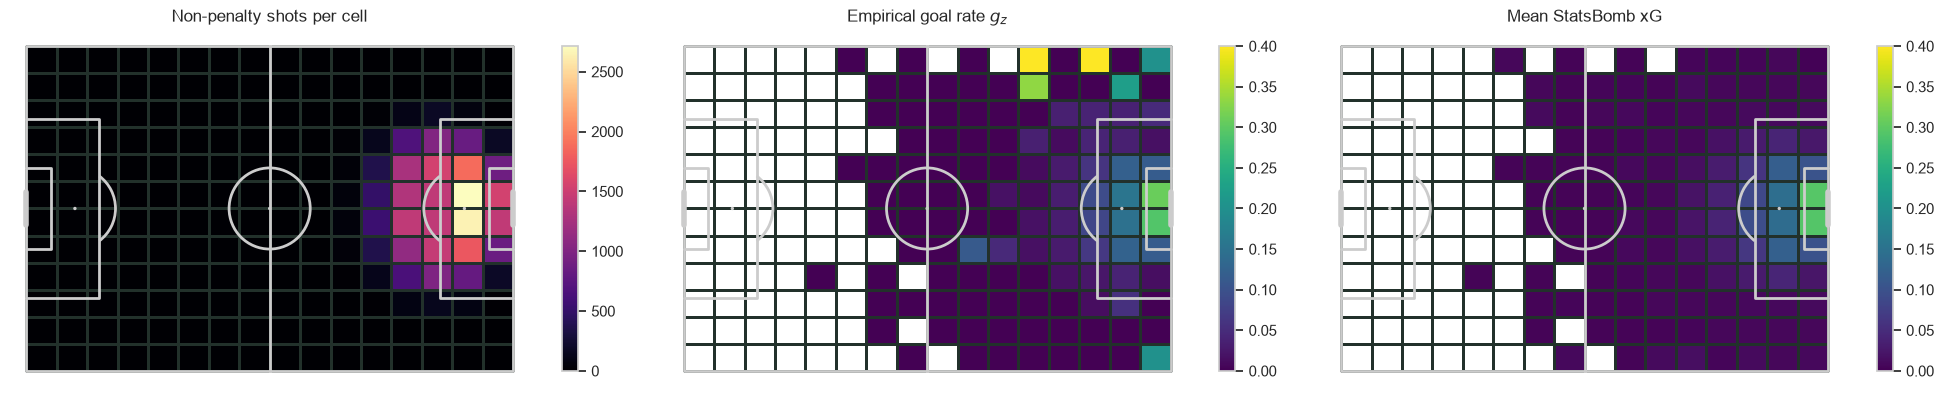

In [14]:
op = shots[shots.sub_type.ne("Penalty")]
n_shots = count_grid(op.x, op.y, NX, NY)
g = count_grid(op.x, op.y, NX, NY, weights=op.is_goal.astype(float))
xg = count_grid(op.x, op.y, NX, NY, weights=op.shot_xg)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
grid_heatmap(n_shots, ax=axes[0], title="Non-penalty shots per cell", cmap="magma")
with np.errstate(invalid="ignore", divide="ignore"):
    grid_heatmap(np.where(n_shots > 0, g / n_shots, np.nan), ax=axes[1], title="Empirical goal rate $g_z$", vmin=0, vmax=0.4)
    grid_heatmap(np.where(n_shots > 0, xg / n_shots, np.nan), ax=axes[2], title="Mean StatsBomb xG", vmin=0, vmax=0.4)
plt.tight_layout(); save(fig, "eda_shots_goal_rate")

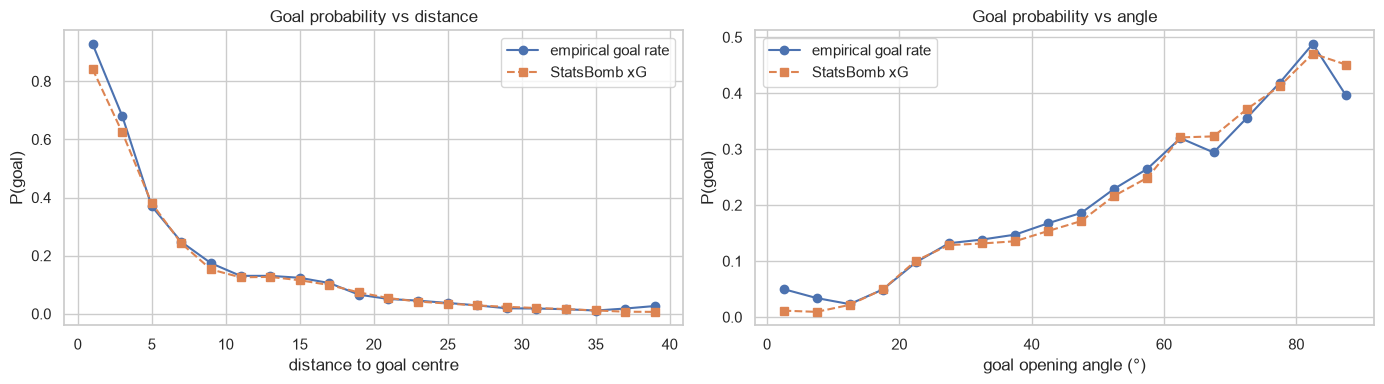

In [15]:
# Distance et angle d'ouverture au but (centre du but en (120, 40), poteaux en y = 36 et 44)
dxg, dyg = PITCH_X - op.x, PITCH_Y / 2 - op.y
op = op.assign(distance=np.hypot(dxg, dyg),
               angle=np.degrees(np.abs(np.arctan2(44 - op.y, dxg) - np.arctan2(36 - op.y, dxg))))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, bins, lab in [(axes[0], "distance", np.arange(0, 42, 2), "distance to goal centre"),
                           (axes[1], "angle", np.arange(0, 95, 5), "goal opening angle (°)")]:
    t = op.groupby(pd.cut(op[col], bins), observed=True).agg(goal_rate=("is_goal", "mean"), xg=("shot_xg", "mean"))
    centers = [i.mid for i in t.index]
    ax.plot(centers, t.goal_rate, "o-", label="empirical goal rate")
    ax.plot(centers, t.xg, "s--", label="StatsBomb xG")
    ax.set_xlabel(lab); ax.set_ylabel("P(goal)"); ax.legend()
axes[0].set_title("Goal probability vs distance"); axes[1].set_title("Goal probability vs angle")
plt.tight_layout(); save(fig, "eda_goal_vs_geometry")

Le taux de but empirique par case est très bruité hors de la surface (cases à 0 % ou à 40 % avec
une poignée de tirs), alors qu'il suit une courbe lisse en fonction de la distance et de l'angle.
Un xG paramétrique (distance, angle) est donc un bon candidat de **prior** pour $g_z$.

## 6. Rareté des données : justifie bien l'idée du xT bayésien

L'estimateur classique de xT est un ratio de comptes par case. Avec peu d'observations, ces
ratios sont instables, surtout pour $g_z$ et pour la matrice de transition $T$
(192 × 192 = 36 864 paires de cases avec la grille 16 × 12).

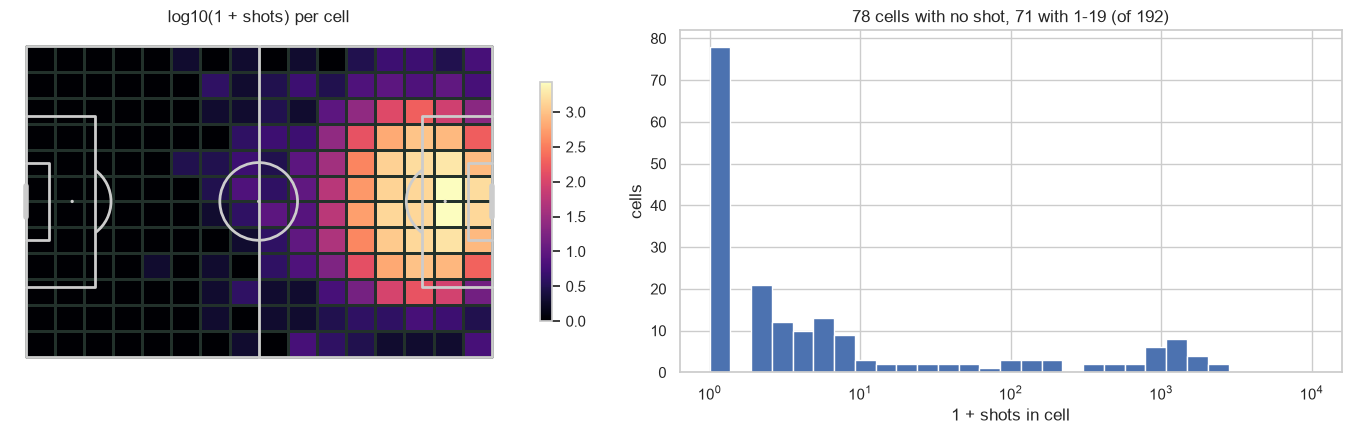

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid_heatmap(np.log10(n_shots + 1), ax=axes[0], title="log10(1 + shots) per cell", cmap="magma")
axes[1].hist(n_shots.ravel() + 1, bins=np.logspace(0, 4, 30))
axes[1].set_xscale("log"); axes[1].set_xlabel("1 + shots in cell"); axes[1].set_ylabel("cells")
axes[1].set_title(f"{(n_shots == 0).sum()} cells with no shot, {((n_shots > 0) & (n_shots < 20)).sum()} with 1-19 (of {n_shots.size})")
plt.tight_layout(); save(fig, "eda_shot_sparsity")

In [17]:
# Rareté de T selon la taille de grille et la quantité de données (mouvements réussis, toutes situations)
okm = ok.loc[~ok.ambiguous_outcome, ["competition_name", "era", "x", "y", "end_x", "end_y", "cell", "end_cell"]]
n_m = actions.groupby("competition_name").match_id.nunique()
datasets = {f"World Cup 2022 ({n_m['FIFA World Cup']} matches)": okm[okm.competition_name.eq("FIFA World Cup")],
            f"Premier League 15/16 ({n_m['Premier League']})": okm[okm.competition_name.eq("Premier League")],
            f"4 leagues 15/16 ({n_m.drop('FIFA World Cup').sum():,})": okm[okm.era.eq("2015/16 leagues")]}
rows = []
for nx, ny in [(8, 6), (12, 8), (16, 12), (24, 16)]:
    for name, sub in datasets.items():
        d = add_cells(sub, nx, ny)
        T = np.zeros((nx * ny, nx * ny))
        np.add.at(T, (d.cell.values, d.end_cell.values), 1)
        nz = T[T > 0]
        rows.append({"grid": f"{nx}x{ny}", "data": name, "moves": len(d), "pairs": T.size,
                     "observed_pairs": nz.size / T.size, "pairs_seen_<5": (nz < 5).mean(),
                     "median_per_pair": np.median(nz)})
sparsity = pd.DataFrame(rows)
sparsity.round(3)

,grid,data,moves,pairs,observed_pairs,pairs_seen_<5,median_per_pair
0,8x6,World Cup 2022 (64 matches),107377,2304,0.634,0.311,11.0
1,8x6,Premier League 15/16 (323),458607,2304,0.762,0.197,32.0
2,8x6,"4 leagues 15/16 (1,289)",1850473,2304,0.826,0.142,100.0
3,12x8,World Cup 2022 (64 matches),107377,9216,0.472,0.477,5.0
4,12x8,Premier League 15/16 (323),458607,9216,0.628,0.316,12.0
5,12x8,"4 leagues 15/16 (1,289)",1850473,9216,0.715,0.204,31.0
6,16x12,World Cup 2022 (64 matches),107377,36864,0.311,0.597,3.0
7,16x12,Premier League 15/16 (323),458607,36864,0.482,0.471,5.0
8,16x12,"4 leagues 15/16 (1,289)",1850473,36864,0.603,0.320,11.0
9,24x16,World Cup 2022 (64 matches),107377,147456,0.182,0.777,2.0


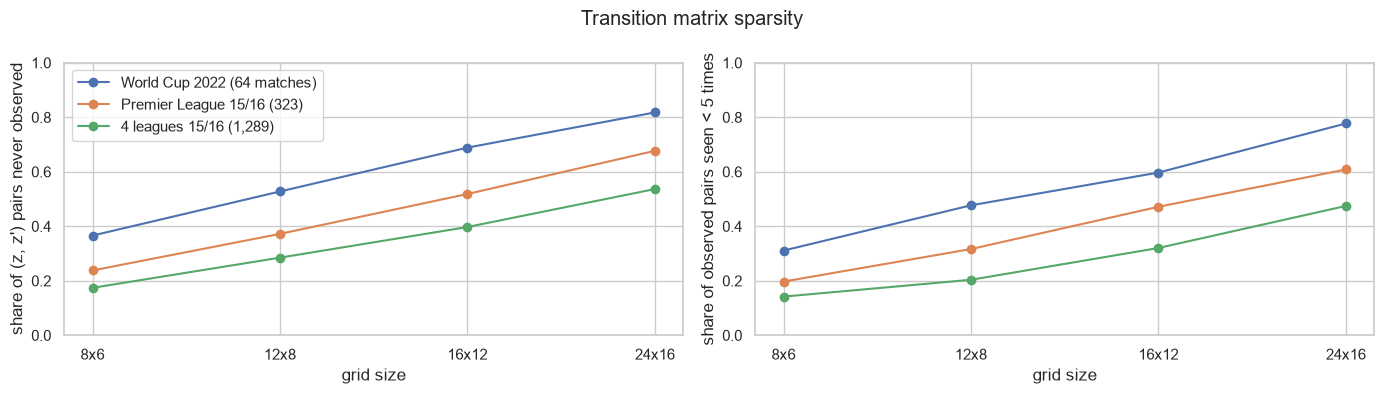

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, d in sparsity.groupby("data", sort=False):
    axes[0].plot(d.grid, 1 - d["observed_pairs"], "o-", label=name)
    axes[1].plot(d.grid, d["pairs_seen_<5"], "o-", label=name)
axes[0].set_ylabel("share of (z, z') pairs never observed")
axes[1].set_ylabel("share of observed pairs seen < 5 times")
for ax in axes:
    ax.set_xlabel("grid size"); ax.set_ylim(0, 1)
axes[0].legend(); fig.suptitle("Transition matrix sparsity")
plt.tight_layout(); save(fig, "eda_transition_sparsity")

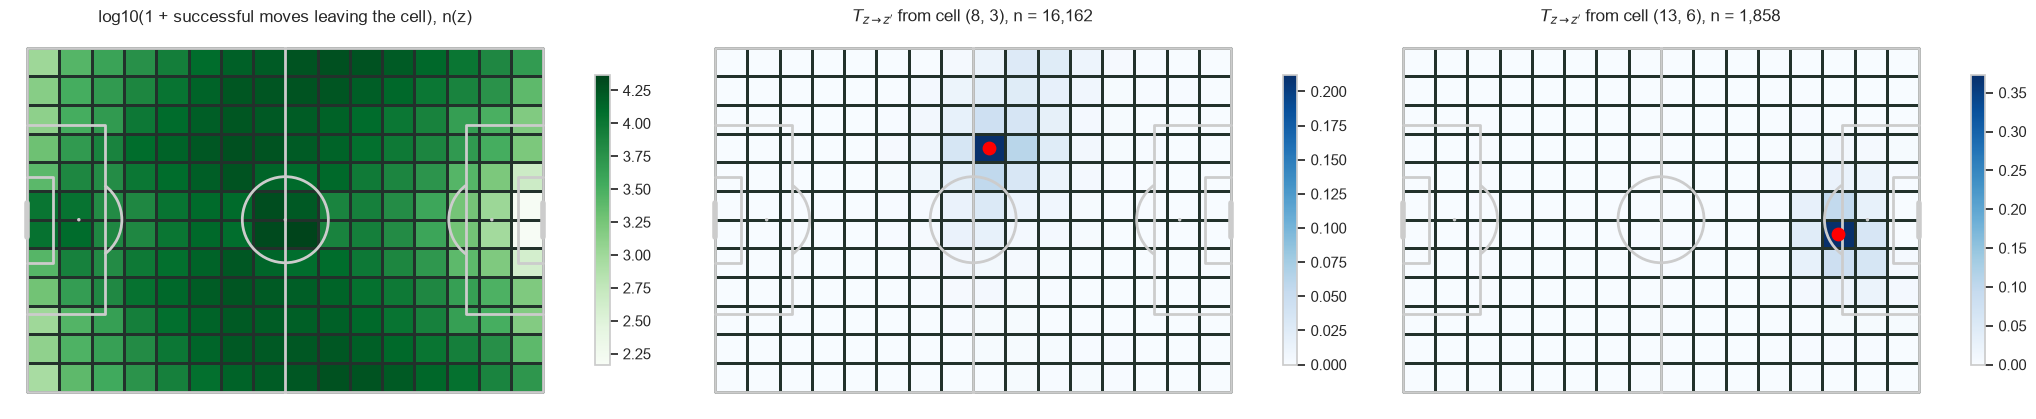

In [19]:
okt = okm[okm.era.eq("2015/16 leagues")]
T = np.zeros((NX * NY, NX * NY))
np.add.at(T, (okt.cell.values, okt.end_cell.values), 1)
fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
grid_heatmap(np.log10(T.sum(1).reshape(NY, NX) + 1), ax=axes[0], cmap="Greens",
             title="log10(1 + successful moves leaving the cell), n(z)")
for ax, (ix, iy) in zip(axes[1:], [(8, 3), (13, 6)]):
    z = iy * NX + ix
    row = T[z].reshape(NY, NX)
    grid_heatmap(row / row.sum(), ax=ax, title=f"$T_{{z \\to z'}}$ from cell ({ix}, {iy}), n = {int(row.sum()):,}", cmap="Blues")
    ax.scatter((ix + 0.5) * PITCH_X / NX, (iy + 0.5) * PITCH_Y / NY, c="red", s=80, zorder=5)
plt.tight_layout(); save(fig, "eda_transition_rows")

Même avec 444 matchs et la grille 16 × 12, environ la moitié des paires $(z, z')$ ne sont jamais
observées et une grande partie des autres le sont moins de 5 fois. Une grille plus fine aggrave
le problème, une grille plus grossière perd en résolution. Chaque ligne de $T$ est une loi catégorielle, donc un **prior de
Dirichlet** (conjugué) est naturel ; et comme les lignes sont lisses dans l'espace, cette distribution à priori peut
mettre plus de masse sur les cases voisines (lissage spatial) ou être partagé entre cases proches.
Cela permet de garder la grille fine 16 × 12 malgré la rareté.

## 7. Jeu ouvert et coups de pied arrêtés

Le xT classique (Singh, 2019) se calcule sur le **jeu ouvert** : un corner, une touche ou un six-mètres
part toujours du même endroit et n'est pas un choix du porteur du ballon. On mesure ce que pèsent
ces actions et où elles se trouvent. Le filtre utilisé partout ensuite est `~set_piece` (l'action
elle-même n'est pas un coup de pied arrêté ; les actions qui suivent une touche restent du jeu ouvert).

In [20]:
# Colonnes utiles aux sections suivantes : on travaille sur des copies étroites pour limiter la mémoire
XT_COLS = ["match_id", "competition_name", "era", "type", "sub_type", "x", "y", "end_x", "end_y", "success",
           "set_piece", "ambiguous_outcome", "is_goal", "shot_xg"]
mv = actions.loc[actions.type.isin(["Pass", "Carry", "Dribble"]) & ~actions.ambiguous_outcome, XT_COLS]
sp_share = (mv.assign(sub_type=mv.sub_type.where(mv.set_piece, "open play"))
              .groupby("sub_type").size().sort_values(ascending=False) / len(mv)).round(4)
print(f"Mouvements de coup de pied arrêté : {mv.set_piece.mean():.1%} des mouvements")
sp_share.to_frame("share of moves")

Mouvements de coup de pied arrêté : 6.0% des mouvements


,share of moves
sub_type,
open play,0.9398
Throw-in,0.0261
Free Kick,0.0166
Goal Kick,0.0092
Corner,0.0057
Kick Off,0.0026


Paires (z, z') observées : 0.608 (tout) contre 0.585 (jeu ouvert)


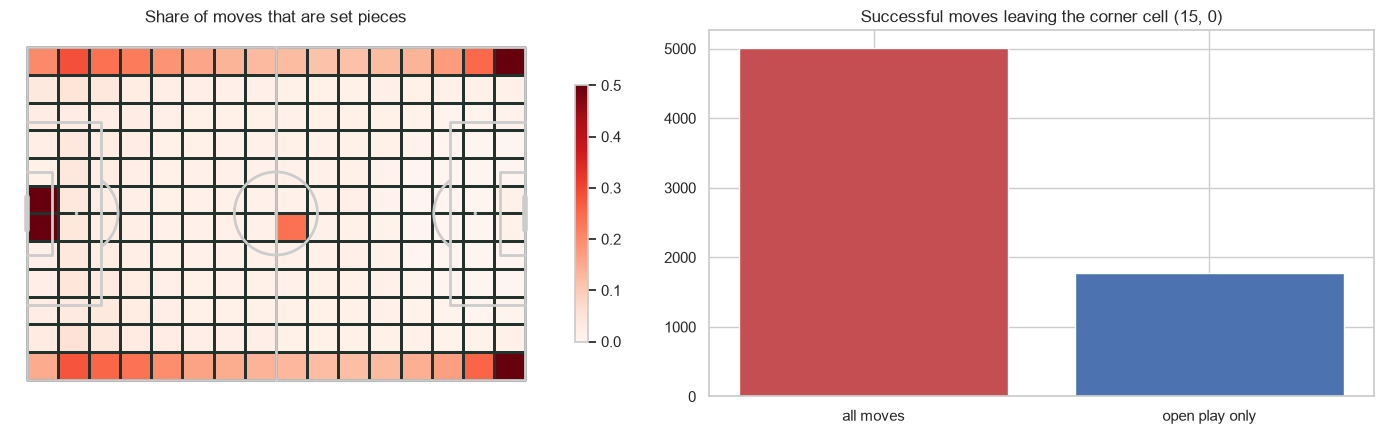

In [21]:
sp = mv[mv.set_piece]
n_all = count_grid(mv.x, mv.y, NX, NY)
with np.errstate(invalid="ignore", divide="ignore"):
    share_sp = np.where(n_all > 0, count_grid(sp.x, sp.y, NX, NY) / n_all, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid_heatmap(share_sp, ax=axes[0], title="Share of moves that are set pieces", cmap="Reds", vmin=0, vmax=0.5)
# effet sur une ligne de T : depuis la case du point de corner adverse
z_corner = 0 * NX + (NX - 1)
N_all = transition_counts(move_cells(actions, NX, NY, open_play=False), NX, NY)
N_op = transition_counts(move_cells(actions, NX, NY, open_play=True), NX, NY)
axes[1].bar(["all moves", "open play only"], [N_all[z_corner].sum(), N_op[z_corner].sum()], color=["C3", "C0"])
axes[1].set_title(f"Successful moves leaving the corner cell ({NX - 1}, 0)")
plt.tight_layout(); save(fig, "eda_set_pieces")
print(f"Paires (z, z') observées : {(N_all > 0).mean():.3f} (tout) contre {(N_op > 0).mean():.3f} (jeu ouvert)")

Les coups de pied arrêtés représentent 6 % des mouvements : touches 2,6 %, coups francs 1,6 %,
six-mètres 0,9 %, corners 0,6 %, coups d'envoi 0,3 %. Ils sont concentrés dans quelques cases (bords, coins, rond central pour les
coups d'envoi) où ils dominent les départs et donc les garder déformerait $T$ dans ces cases. Regarder le graphique qui montre les données depuis la case du point de corner, ~6 000 mouvements réussis
au total mais seulement ~2 100 en jeu ouvert.  

**Choix :**
$s_z$, $m_z$, $T$ et $g_z$ sont estimés sur le jeu ouvert (`move_cells(..., open_play=True)` et
`action_probabilities(..., open_play=True)`). Les coups de pied arrêtés pourront être modélisés à
part ou ignorés (comme dans Singh, 2019).

## 8. Les quantités de la récursion xT et les états absorbants

Le modèle qu'on estime est une chaîne de Markov absorbante sur les 192 cases. Le porteur du ballon
en $z$ :

* **tire** avec probabilité $s_z$ : but avec probabilité $g_z$ (état absorbant « but »), sinon état
  absorbant « tir raté » ;
* **déplace le ballon** avec probabilité $m_z = 1 - s_z$ (passe, conduite ou dribble) :
  * réussite avec probabilité $p_z$, et le ballon va en $z'$ avec probabilité $T_{z \to z'}$
    (normalisée sur les mouvements réussis) ;
  * échec avec probabilité $1 - p_z$ : état absorbant « ballon perdu » (valeur 0 dans le xT
    classique ; voir l'extension « risque défensif » plus tard).

Ainsi $xT(z) = s_z g_z + m_z\, p_z \sum_{z'} T_{z \to z'} xT(z')$ (c'est la formule de Singh si
on définit sa matrice comme $p_z T_{z \to z'}$ (lignes qui somment au taux de réussite)).

Conventions : penalties exclus, jeu ouvert seulement, passes ambiguës retirées, un dribble réussi
reste dans sa case (la conduite qui suit déplace le ballon).

cells with no action                0.000
cells with no shot                 83.000
max s_z                             0.850
share of actions that are shots     0.014
overall move success                0.844
dtype: float64

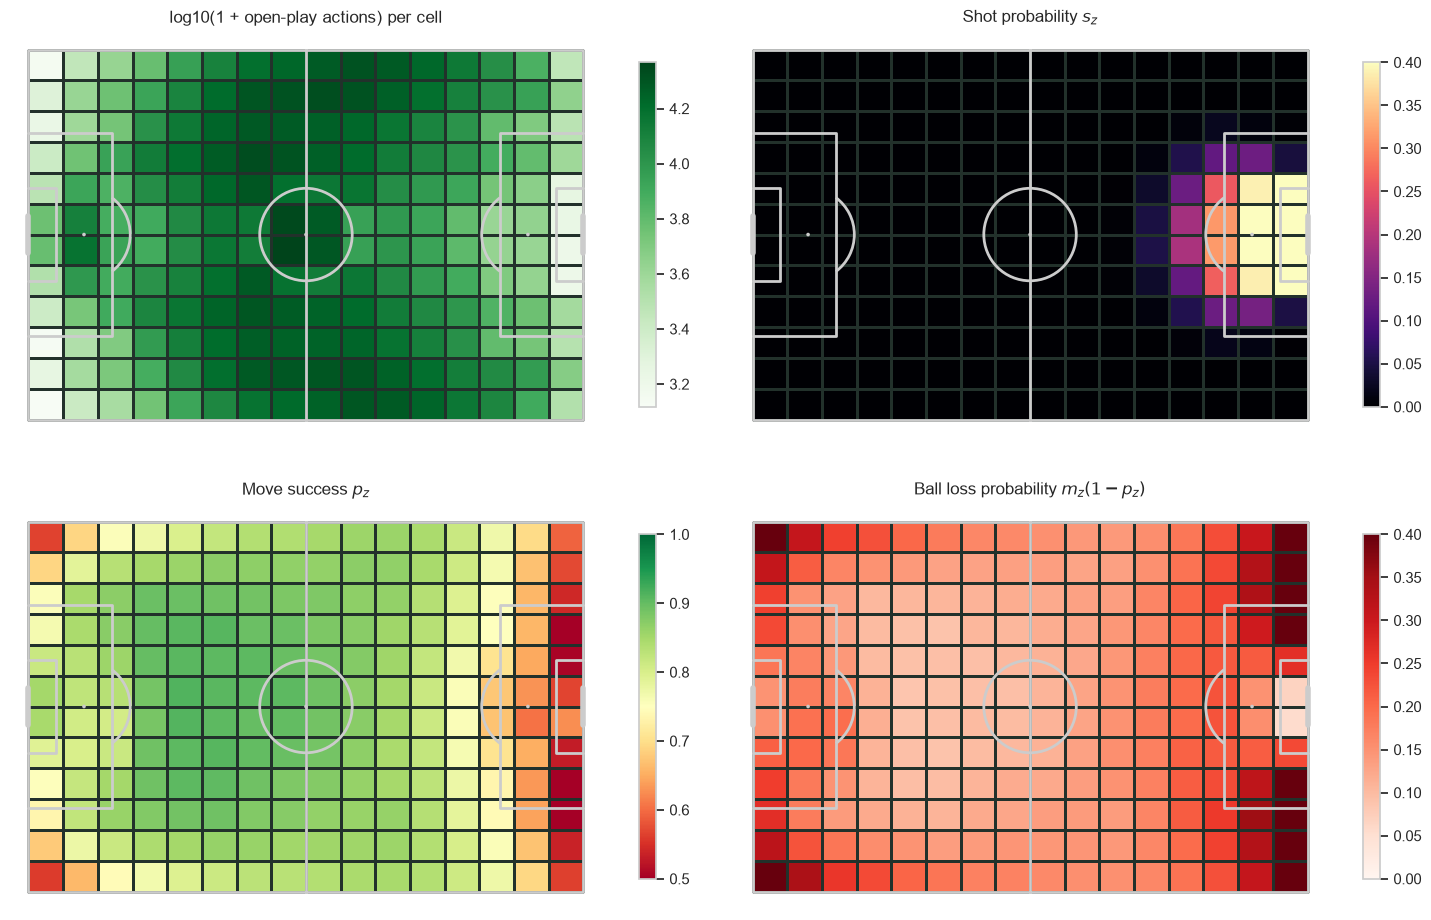

In [34]:
P = action_probabilities(actions.loc[actions.era.eq("2015/16 leagues"), XT_COLS], NX, NY, open_play=True)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
grid_heatmap(np.log10(P["n_actions"] + 1), ax=axes[0, 0], title="log10(1 + open-play actions) per cell", cmap="Greens")
grid_heatmap(P["s"], ax=axes[0, 1], title="Shot probability $s_z$", cmap="magma", vmin=0, vmax=0.4)
grid_heatmap(P["move_success"], ax=axes[1, 0], title="Move success $p_z$", cmap="RdYlGn", vmin=0.5, vmax=1)
grid_heatmap(P["p_loss"], ax=axes[1, 1], title="Ball loss probability $m_z (1 - p_z)$", cmap="Reds", vmin=0, vmax=0.4)
plt.tight_layout(); save(fig, "eda_action_probabilities")
pd.Series({"cells with no action": int((P["n_actions"] == 0).sum()),
           "cells with no shot": int((P["n_shots"] == 0).sum()),
           "max s_z": np.nanmax(P["s"]),
           "share of actions that are shots": P["n_shots"].sum() / P["n_actions"].sum(),
           "overall move success": np.nansum(P["move_success"] * P["n_moves"]) / P["n_moves"].sum()}).round(3)

On tire presque uniquement depuis la surface et ses abords : $s_z$ dépasse 0,4 dans les cases
centrales de la surface (jusqu'à 0,85 dans une case des six mètres, avec peu d'actions) et il est
quasi nul ailleurs ; 1,4 % des actions sont des tirs. 83 cases n'ont aucun tir en jeu ouvert. La réussite des mouvements (84,4 % en moyenne) baisse fortement dans le
dernier tiers et tombe vers 50 % le long de la ligne de but adverse, où la probabilité de perdre le
ballon est la plus forte (plus de 35 % dans les coins). Les cases de la surface ont peu d'actions :
c'est là que $s_z$ et $g_z$ sont les plus incertains, et là que xT est le plus élevé. Le prior a
donc le plus d'effet exactement là où xT compte le plus.

## 9. Les 4 championnats se ressemblent-ils ?

Si les ligues ont des comportements différents, il serait pertinent d'utiliser un **modèle hiérarchique** (un paramètre par
ligue tiré d'une loi commune) plutôt que tout regrouper. On compare d'abord des statistiques
globales, puis les lignes de $T$ case par case.

In [23]:
L = actions.loc[actions.era.eq("2015/16 leagues"), XT_COLS]
mvL, shL = L[L.type.isin(["Pass", "Carry", "Dribble"]) & ~L.ambiguous_outcome], L[L.type.eq("Shot") & L.sub_type.ne("Penalty")]
nm = L.groupby("competition_name").match_id.nunique()
league_stats = pd.DataFrame({
    "matches": nm,
    "passes / match": mvL[mvL.type.eq("Pass")].groupby("competition_name").size() / nm,
    "pass success": mvL[mvL.type.eq("Pass")].groupby("competition_name").success.mean(),
    "carry success": mvL[mvL.type.eq("Carry")].groupby("competition_name").success.mean(),
    "shots / match (no pen.)": shL.groupby("competition_name").size() / nm,
    "conversion (no pen.)": shL.groupby("competition_name").is_goal.mean(),
    "StatsBomb xG / shot": shL.groupby("competition_name").shot_xg.mean(),
})
league_stats.round(3)

,matches,passes / match,pass success,carry success,shots / match (no pen.),conversion (no pen.),StatsBomb xG / shot
competition_name,,,,,,,
La Liga,323,954.402,0.764,0.938,23.774,0.103,0.100
Ligue 1,320,985.947,0.775,0.93,22.869,0.096,0.092
Premier League,323,962.845,0.77,0.933,25.904,0.092,0.091
Serie A,323,969.362,0.78,0.938,26.152,0.088,0.084


169 cases comparées. JS moyen intra-ligue = 0.0264, inter-ligues = 0.0276


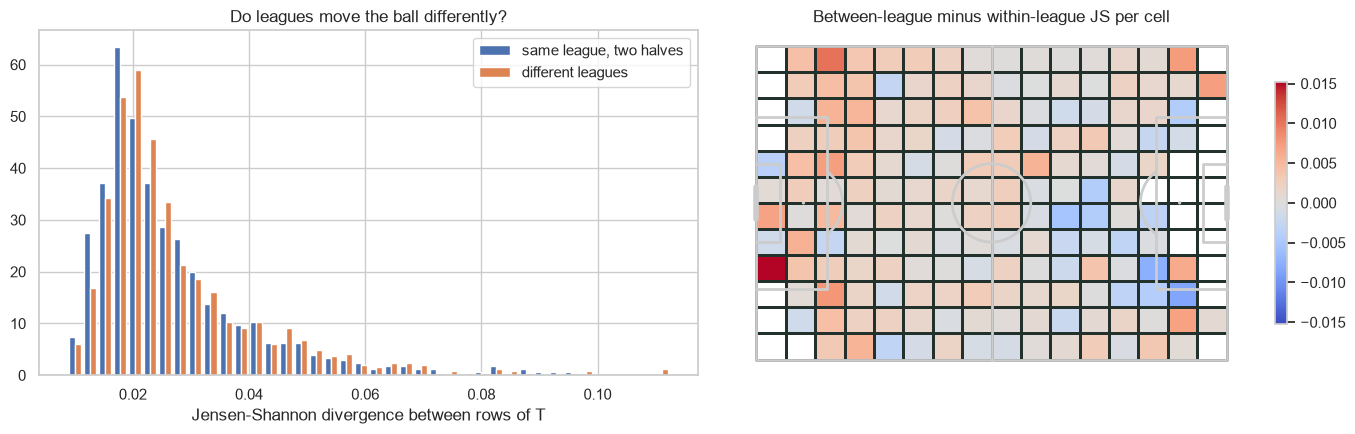

In [24]:
# Divergence de Jensen-Shannon entre lignes de T, à taille d'échantillon égale :
# chaque ligue est coupée en deux moitiés de matchs (h1, h2).
#   intra-ligue  : JS(ligue_h1, ligue_h2)      -> bruit d'échantillonnage seul
#   inter-ligues : JS(ligueA_h1, ligueB_h1)    -> bruit + vraies différences
from itertools import combinations
from scipy.spatial.distance import jensenshannon

rng = np.random.default_rng(0)
mvo = move_cells(L, NX, NY, open_play=True)
halves = {}
for comp, d in mvo.groupby("competition_name"):
    ids = d.match_id.unique(); rng.shuffle(ids)
    h1 = set(ids[: len(ids) // 2])
    halves[comp] = [transition_counts(d[d.match_id.isin(h1)], NX, NY),
                    transition_counts(d[~d.match_id.isin(h1)], NX, NY)]
min_n = 200   # cases avec au moins 200 mouvements réussis dans chaque moitié de chaque ligue
ok_cells = np.all([h.sum(1) >= min_n for hs in halves.values() for h in hs], axis=0)

def js_rows(A, B):
    return np.array([jensenshannon(A[z], B[z]) ** 2 for z in np.where(ok_cells)[0]])

within = np.concatenate([js_rows(*halves[c]) for c in halves])
between = np.concatenate([js_rows(halves[a][0], halves[b][0]) for a, b in combinations(halves, 2)])
print(f"{ok_cells.sum()} cases comparées. JS moyen intra-ligue = {within.mean():.4f}, inter-ligues = {between.mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist([within, between], bins=40, label=["same league, two halves", "different leagues"], density=True)
axes[0].set_xlabel("Jensen-Shannon divergence between rows of T"); axes[0].legend()
axes[0].set_title("Do leagues move the ball differently?")
excess = np.full(NX * NY, np.nan)
excess[ok_cells] = (np.mean([js_rows(halves[a][0], halves[b][0]) for a, b in combinations(halves, 2)], axis=0)
                    - np.mean([js_rows(*halves[c]) for c in halves], axis=0))
grid_heatmap(excess.reshape(NY, NX), ax=axes[1], title="Between-league minus within-league JS per cell", cmap="coolwarm",
             vmin=-np.nanmax(np.abs(excess)), vmax=np.nanmax(np.abs(excess)))
plt.tight_layout(); save(fig, "eda_league_differences")

La lecture des sorties ici est pas super intuitive mais en gros, si la divergence entre ligues n'est pas plus grande que celle entre deux moitiés d'une même ligue, nous pouvons interpeter les differences comme du bruit d'échantillonnage et regrouper les 4 ligues, tandis que si elle est plus grande une partie des différences est réelle. 

Dans notre cas, sur les 169 cases comparées, la divergence inter-ligues est (0,0276) et dépasse d'environ 5% la divergence intra-ligue (0,0264) et l'écart est positif dans la plupart des cases. Il existe donc de vraies différences entre les ligues, mais elles restent petites devant le bruit d'échantillonage. Certaines différences sont aussi plus marquées, par exemple pour les tirs la conversion hors penalties de 8,8% en Serie A vs 10.3 % en La Liga est plus significative.

Un modèle hiérarchique par ligue est donc justifié, cependant regrouper les 4 ligues est pas mal plus simple et reste une bonne approximation pour le xT de référence.

## 10. Possessions

xT prétend mesurer la probabilité de marquer « dans les prochaines actions » d'une possession. Pour
le valider il faut savoir comment les possessions se déroulent et se terminent. `possession_table`
résume chaque possession StatsBomb (actions de l'équipe qui a le ballon seulement).

In [25]:
poss = possession_table(actions)
poss["era"] = np.where(poss.competition_name.isin(RECENT), "World Cup 2022", "2015/16 leagues")
poss = poss[poss.n_actions > 0]
summary_poss = poss.groupby("era").agg(possessions=("possession", "size"),
                                       mean_actions=("n_actions", "mean"), median_actions=("n_actions", "median"),
                                       mean_duration_s=("duration", "mean"), with_shot=("has_shot", "mean"),
                                       with_goal=("has_goal", "mean"))
summary_poss["per_match"] = summary_poss.possessions / actions.groupby("era").match_id.nunique()
summary_poss.round(3)

,possessions,mean_actions,median_actions,mean_duration_s,with_shot,with_goal,per_match
era,,,,,,,
2015/16 leagues,248631,8.589,6.0,14.579,0.118,0.013,192.887
World Cup 2022,10741,11.156,7.0,18.830,0.119,0.015,167.828


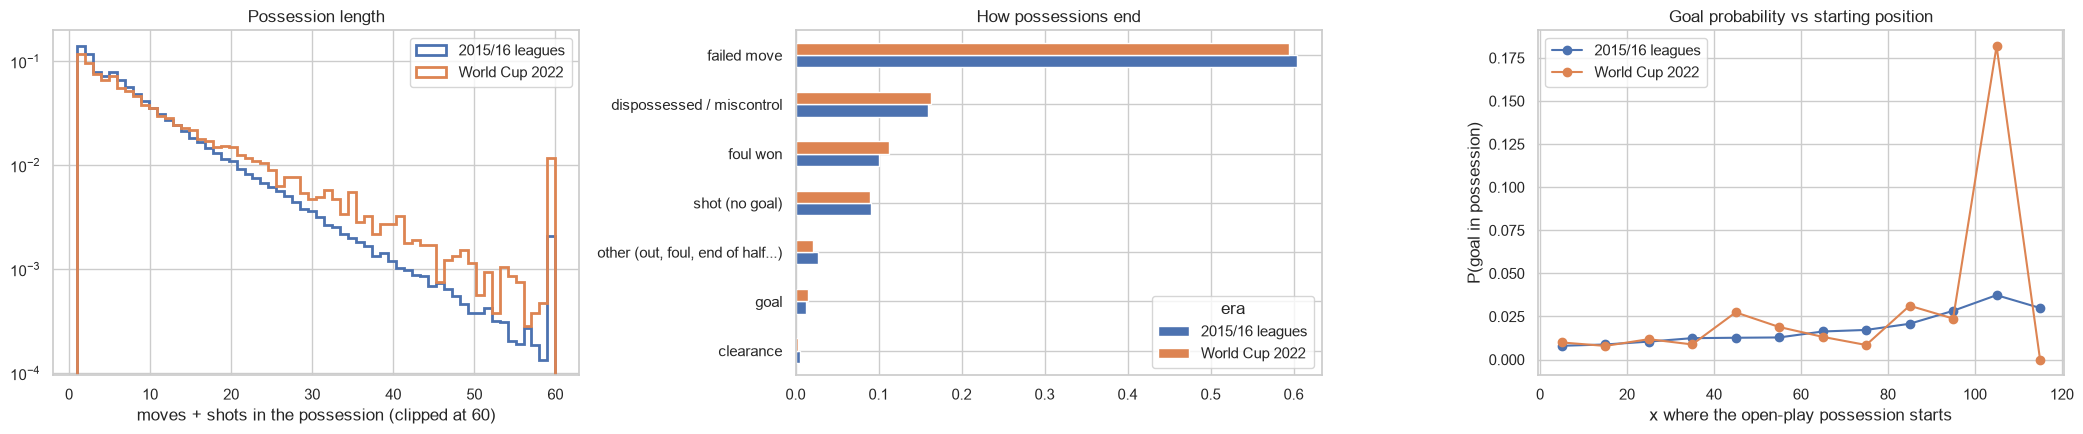

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
for era, d in poss.groupby("era"):
    axes[0].hist(d.n_actions.clip(upper=60), bins=60, density=True, histtype="step", lw=2, label=era)
axes[0].set_xlabel("moves + shots in the possession (clipped at 60)"); axes[0].set_yscale("log"); axes[0].legend()
axes[0].set_title("Possession length")
(poss.groupby("era").end_type.value_counts(normalize=True).unstack(0)
     .sort_values("2015/16 leagues").plot.barh(ax=axes[1]))
axes[1].set_title("How possessions end"); axes[1].set_ylabel("")
bins = np.arange(0, 121, 10)
for era, d in poss[~poss.set_piece_start].groupby("era"):
    t = d.groupby(pd.cut(d.start_x, bins), observed=True).has_goal.mean()
    axes[2].plot([iv.mid for iv in t.index], t.values, "o-", label=era)
axes[2].set_xlabel("x where the open-play possession starts"); axes[2].set_ylabel("P(goal in possession)")
axes[2].set_title("Goal probability vs starting position"); axes[2].legend()
plt.tight_layout(); save(fig, "eda_possessions")

La plupart des possessions sont courtes (8,6 actions en moyenne en 2015/16, médiane 6) et ~76 %
se terminent par une perte de balle (mouvement raté ou dépossession) ; 11,8 % contiennent un tir et
1,3 % un but. La probabilité de marquer dans la
possession passe d'environ 0,8 % (possession commencée près de son propre but) à environ 4 %
(commencée à 15-25 m du but adverse) : c'est déjà un
« xT » très grossier (une seule dimension, sans modèle), qui servira de contrôle de cohérence. La
courbe de la Coupe du monde 2022, très irrégulière avec 64 matchs, illustre à nouveau la rareté des données.

**Validation de xT prévue** : sur les matchs test, comparer xT de la case de départ d'une possession
à l'issue observée (but ou non) par log loss / Brier, contre ce profil empirique.

## 11. Freeze frames des tirs : des positions de joueurs pour toutes les saisons

Chaque tir StatsBomb, y compris en 2015/16, contient un `freeze_frame` : la position des joueurs
proches au moment du tir. `clean.py` en tire des variables (`ff_*`, voir
`shot_freeze_frame_features`) : adversaires dans le triangle tireur-poteaux, position du gardien,
pression (adversaires à moins de 2 unités), et part de l'angle d'ouverture du but non masquée par
les adversaires (même idée que l'angle de Kos utilisé par le DxT mais pas la formule exacte). Ce sont
les candidates naturelles pour notre xG bayésien.

In [27]:
sh = actions[actions.type.eq("Shot") & actions.sub_type.ne("Penalty")].copy()
sh["distance"] = np.hypot(PITCH_X - sh.x, PITCH_Y / 2 - sh.y)
ff_cols = ["ff_n_opp_triangle", "ff_gk_in_triangle", "ff_gk_dist_goal", "ff_n_opp_close", "ff_visible_frac"]
print(f"Tirs (hors penalties) avec freeze frame : {sh.ff_visible_frac.notna().mean():.1%}")
sh[ff_cols + ["shot_first_time"]].describe().T.round(2)

Tirs (hors penalties) avec freeze frame : 100.0%


,count,mean,std,min,25%,50%,75%,max
ff_n_opp_triangle,33241.0,0.77,0.97,0.0,0.00,1.00,1.00,8.00
ff_gk_in_triangle,33241.0,0.96,0.19,0.0,1.00,1.00,1.00,1.00
ff_gk_dist_goal,33212.0,3.49,2.42,0.1,2.02,3.04,4.20,70.38
ff_n_opp_close,33241.0,0.51,0.68,0.0,0.00,0.00,1.00,4.00
ff_visible_frac,33239.0,0.37,0.24,0.0,0.17,0.38,0.57,1.00


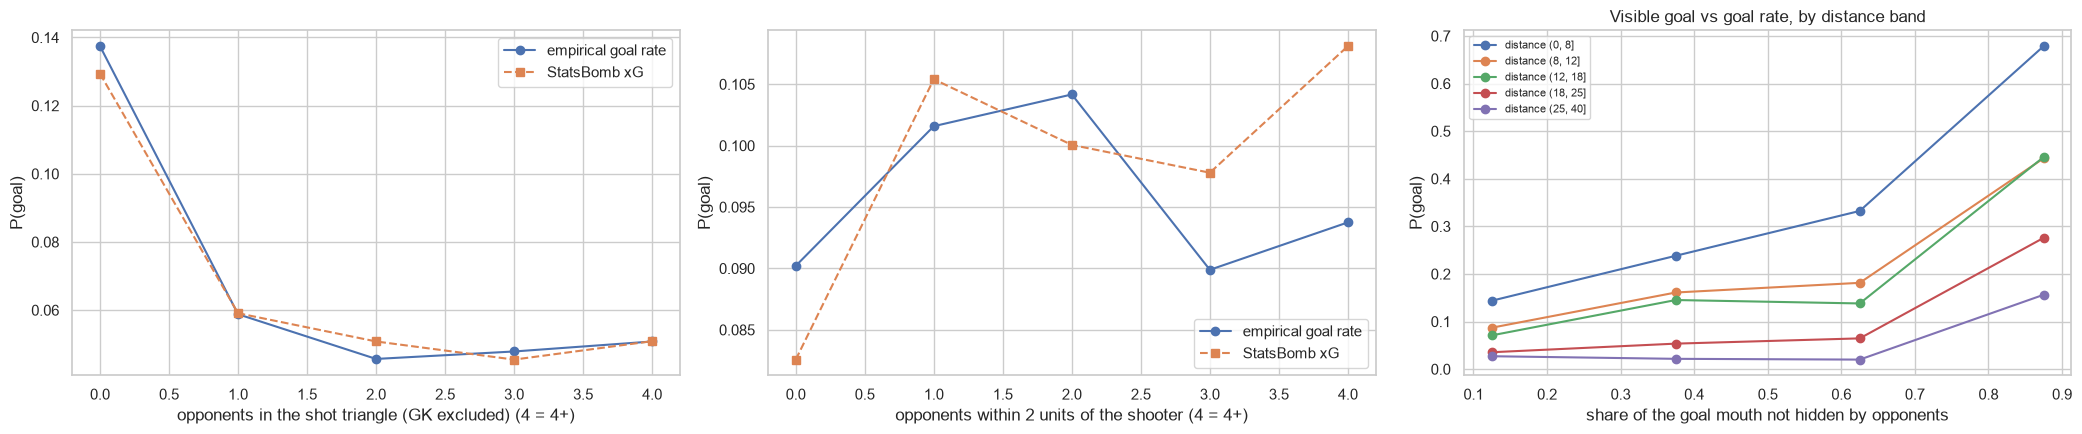

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
for ax, col, lab in [(axes[0], "ff_n_opp_triangle", "opponents in the shot triangle (GK excluded)"),
                     (axes[1], "ff_n_opp_close", "opponents within 2 units of the shooter")]:
    t = sh.assign(k=sh[col].clip(upper=4)).groupby("k").agg(goal_rate=("is_goal", "mean"), xg=("shot_xg", "mean"), n=("is_goal", "size"))
    ax.plot(t.index, t.goal_rate, "o-", label="empirical goal rate"); ax.plot(t.index, t.xg, "s--", label="StatsBomb xG")
    ax.set_xlabel(lab + " (4 = 4+)"); ax.set_ylabel("P(goal)"); ax.legend()
# l'angle visible apporte-t-il de l'information au-delà de la distance ?
sh["dist_band"] = pd.cut(sh.distance, [0, 8, 12, 18, 25, 40])
for band, d in sh.groupby("dist_band", observed=True):
    t = d.groupby(pd.cut(d.ff_visible_frac, [0, .25, .5, .75, 1.0001], include_lowest=True), observed=True).is_goal.mean()
    axes[2].plot([iv.mid for iv in t.index], t.values, "o-", label=f"distance {band}")
axes[2].set_xlabel("share of the goal mouth not hidden by opponents"); axes[2].set_ylabel("P(goal)")
axes[2].set_title("Visible goal vs goal rate, by distance band"); axes[2].legend(fontsize=8)
plt.tight_layout(); save(fig, "eda_freeze_frame")

Le taux de but chute avec le nombre d'adversaires dans le triangle de tir, et, **à distance égale**,
augmente avec la part du but visible : ces variables apportent de l'information que la distance et
l'angle seuls n'ont pas. La pression (adversaires proches du tireur) a un effet non monotone parce
qu'elle est confondue avec la distance : les tirs de près, plus dangereux, sont aussi les plus
entourés. Seul un modèle multivarié peut séparer ces effets. Le xG de StatsBomb suit bien ces tendances (il utilise lui aussi le freeze
frame) : c'est la référence à battre ou à égaler. Ces variables entreront dans le xG bayésien
(régression logistique, priors sur les coefficients, effet par ligue), puis dans $g_z$ et $s_z$ à la
manière du DxT.

## 12. 2015/16 contre le football récent (Coupe du monde 2022)

Il n'existe pas de saison de championnat masculin récente complète dans l'open data. L'idée est donc
d'apprendre sur 2015/16 et de transférer vers les tournois récents. On mesure ici en quoi ils
diffèrent, avec la Coupe du monde 2022 seulement(on garde l'Euro 2024 pour le test).
La différence mélange l'**époque** (2015 contre 2022-2024) et le **type de compétition**
(clubs contre sélections nationales en tournoi) (on ne peut pas isoler que l'époque avec ces données).

In [29]:
def era_stats(d):
    m = d.match_id.nunique()
    mvd, shd = d[d.type.isin(["Pass", "Carry", "Dribble"]) & ~d.ambiguous_outcome], d[d.type.eq("Shot") & d.sub_type.ne("Penalty")]
    dist = np.hypot(PITCH_X - shd.x, PITCH_Y / 2 - shd.y)
    return pd.Series({"matches": m,
                      "passes / match": mvd.type.eq("Pass").sum() / m,
                      "carries / match": mvd.type.eq("Carry").sum() / m,
                      "pass success": mvd[mvd.type.eq("Pass")].success.mean(),
                      "carry success": mvd[mvd.type.eq("Carry")].success.mean(),
                      "dribble success": mvd[mvd.type.eq("Dribble")].success.mean(),
                      "shots / match (no pen.)": len(shd) / m,
                      "mean shot distance": dist.mean(),
                      "share of shots outside the box": (shd.x < 102).mean(),
                      "StatsBomb xG / shot": shd.shot_xg.mean(),
                      "conversion (no pen.)": shd.is_goal.mean()})

drift = actions[XT_COLS].groupby("era").apply(era_stats).T
drift.round(3)

era,2015/16 leagues,World Cup 2022
matches,1289.000,64.000
passes / match,968.098,1063.734
carries / match,735.671,840.062
pass success,0.773,0.828
carry success,0.935,0.949
dribble success,0.554,0.523
shots / match (no pen.),24.679,22.344
mean shot distance,19.645,18.457
share of shots outside the box,0.418,0.372
StatsBomb xG / shot,0.091,0.096


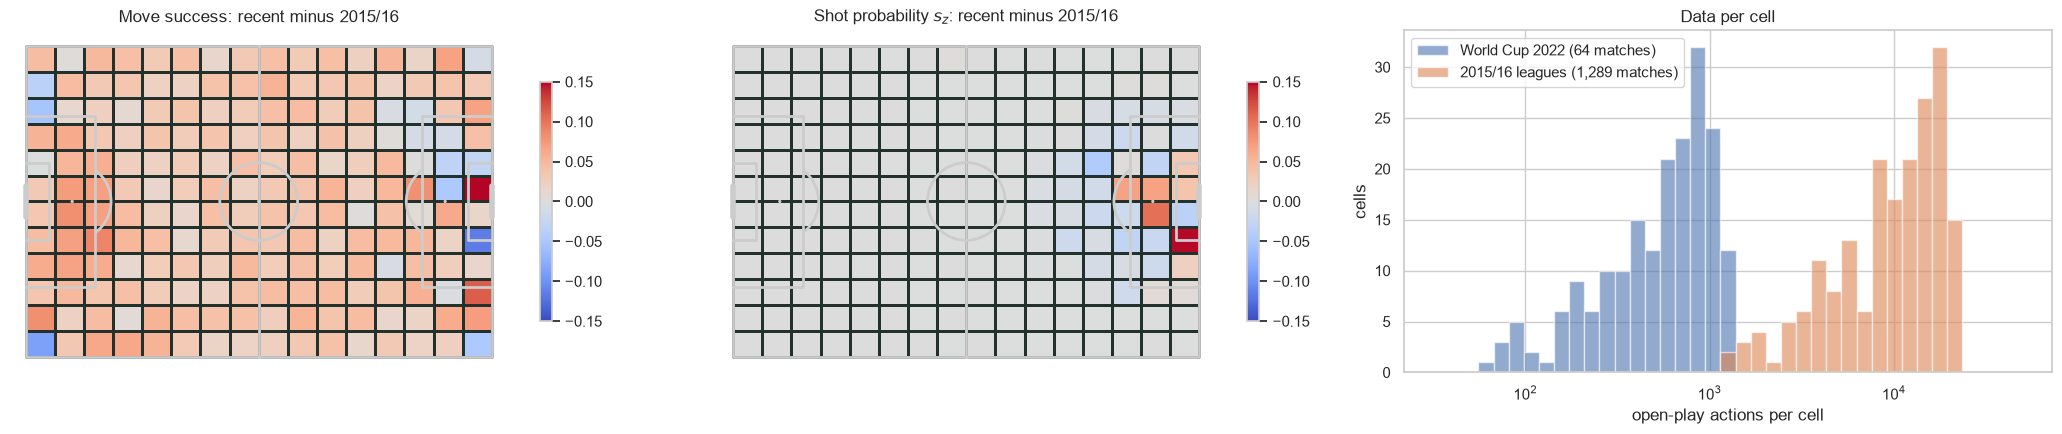

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
P_old = P   # section 8 : 4 championnats 2015/16, jeu ouvert
P_new = action_probabilities(actions.loc[actions.era.eq("World Cup 2022"), XT_COLS], NX, NY)
diff = P_new["move_success"] - P_old["move_success"]
grid_heatmap(diff, ax=axes[0], title="Move success: recent minus 2015/16", cmap="coolwarm", vmin=-0.15, vmax=0.15)
diff_s = P_new["s"] - P_old["s"]
grid_heatmap(diff_s, ax=axes[1], title="Shot probability $s_z$: recent minus 2015/16", cmap="coolwarm", vmin=-0.15, vmax=0.15)
bins_n = np.logspace(1.5, 4.7, 40)
n_era = actions.groupby("era").match_id.nunique()
axes[2].hist(P_new["n_actions"].ravel(), bins=bins_n, alpha=0.6, label=f"World Cup 2022 ({n_era['World Cup 2022']} matches)")
axes[2].hist(P_old["n_actions"].ravel(), bins=bins_n, alpha=0.6, label=f"2015/16 leagues ({n_era['2015/16 leagues']:,} matches)")
axes[2].set_xscale("log"); axes[2].set_xlabel("open-play actions per cell"); axes[2].set_ylabel("cells"); axes[2].legend()
axes[2].set_title("Data per cell")
plt.tight_layout(); save(fig, "eda_era_drift")

La Coupe du monde 2022 a plus de passes (1 064 contre 968 par match), une meilleure réussite des
passes (82,8 % contre 77,3 %, plus haute presque partout sur le terrain) et des possessions plus
longues. On y tire un peu moins (22,3 contre 24,7 tirs par match hors penalties) mais de plus près
(37 % des tirs hors de la surface contre 42 %), d'où un xG StatsBomb par tir un peu plus élevé
(0,096 contre 0,091). Elle a environ 20 fois moins de données par case (64 matchs contre 1 289). C'est exactement le cadre où un prior aide : le récent seul donne des
estimations très bruitées, tandis que 2015/16 seul est biaisé pour le football d'aujourd'hui. Le
xT bayésien combine les deux : **prior appris sur 2015/16, mis à jour avec les données récentes**,
et la force du prior (concentration du Dirichlet, ou variance d'un effet « époque » hiérarchique)
dit combien on fait confiance à l'ancien.

## 13. Découpage train / validation / test et métriques

Le découpage se fait par match (au lieu de par action, puisque
deux actions d'un même match ne sont pas indépendantes), stratifié par championnat : 70 % train,
15 % validation, 15 % test pour les 4 ligues 2015/16 ; Coupe du monde 2022 en `recent_val`, Euro
2024 en `recent_test` (voir le protocole en section 0). Le tableau ci-dessous ne montre que les
nombres de matchs. Le fichier est écrit
dans `data/processed/split.csv` ; les autres notebooks le relisent avec `load_split()` et ne
chargent que `eda_matches(split)` pendant le développement.

La référence est calculée sur `val` et `recent_val` seulement :
sur les tirs hors penalties, le xG StatsBomb obtient une log loss de 0,240 sur `val` et 0,267 sur
`recent_val`, contre 0,308 et 0,339 pour une probabilité constante (Brier 0,067 et 0,076 contre
0,084 et 0,095). C'est la référence pour notre xG ; la comparaison finale se fera une seule fois
sur `test` et `recent_test`.

Métriques pour toute probabilité (xG, réussite d'une passe, but dans la possession) : **log loss**
(la log-vraisemblance prédictive, naturelle en bayésien), **Brier**, et une **courbe de calibration**.

In [31]:
# Construit et sauvegardé en section 0 ; ici seulement les effectifs (aucune donnée des jeux de test)
split.groupby(["competition_name", "split"]).size().unstack(fill_value=0)

split,recent_test,recent_val,test,train,val
competition_name,,,,,
FIFA World Cup,0,64,0,0,0
La Liga,0,0,57,266,57
Ligue 1,0,0,57,263,57
Premier League,0,0,57,266,57
Serie A,0,0,57,266,57
UEFA Euro,51,0,0,0,0


In [35]:
# Référence à battre : le xG StatsBomb, sur les tirs hors penalties de val et recent_val 
shs = sh.merge(split[["match_id", "split"]], on="match_id")
base_rate = shs[shs.split.eq("train")].is_goal.mean()
rows = []
for name in ["val", "recent_val"]:
    d = shs[shs.split.eq(name)]
    rows.append({"split": name, "shots": len(d),
                 "log loss, constant (train rate)": log_loss(d.is_goal, np.full(len(d), base_rate)),
                 "log loss, StatsBomb xG": log_loss(d.is_goal, d.shot_xg),
                 "Brier, constant": brier(d.is_goal, np.full(len(d), base_rate)),
                 "Brier, StatsBomb xG": brier(d.is_goal, d.shot_xg)})
xg_baseline = pd.DataFrame(rows).set_index("split")
xg_baseline.round(4)

,shots,"log loss, constant (train rate)","log loss, StatsBomb xG","Brier, constant","Brier, StatsBomb xG"
split,,,,,
val,5472,0.3083,0.2402,0.0839,0.0673
recent_val,1430,0.3394,0.2665,0.0951,0.0762


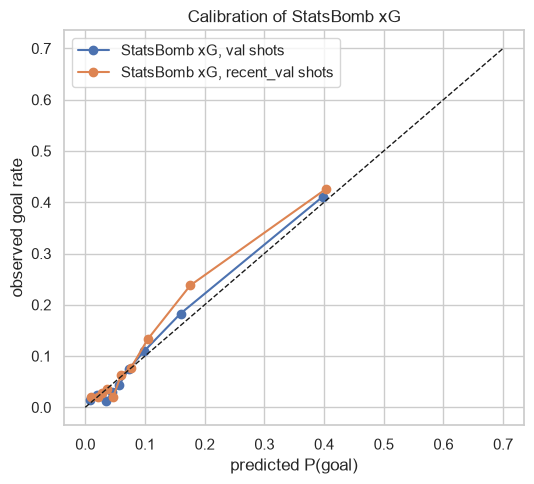

In [36]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name in ["val", "recent_val"]:
    d = shs[shs.split.eq(name)]
    c = calibration_table(d.is_goal, d.shot_xg, bins=10)
    ax.plot(c.predicted, c.observed, "o-", label=f"StatsBomb xG, {name} shots")
ax.plot([0, 0.7], [0, 0.7], "k--", lw=1)
ax.set_xlabel("predicted P(goal)"); ax.set_ylabel("observed goal rate"); ax.legend()
ax.set_title("Calibration of StatsBomb xG")
plt.tight_layout(); save(fig, "eda_xg_calibration")

# Résumé 

#### Données
- On considère que les ligues/tournois masculins et ceux pour lesquelles nous avons la saison complète (pas le suivi d'une seule équipe ou que les finales)
- Pour le nettoyage les tirs au but retirés (ce n'est pas du jeu : penalty sans défense, biaiserait $g_z$),
  coordonnées ramenées dans le terrain 120 × 80, passes `Unknown` / `Injury Clearance` marquées comme
  ambiguës (10 707 passes : ce ne sont pas de vraies pertes de balle), penalties (358) et coups de pied
  arrêtés marqués pour être traités à part (section 2). Les buts contre son camp (116 des
  3 539 buts, 3 %) ne sont pas des tirs et ne comptent donc pas dans $g_z$.
- Le split final est le suivant : Entraînement sur 70% des données de la Premier League, la Liga, la Serie A et la Ligue 1 de 2015/2016 (1061 matchs). 15% de ces données sont utilisés pour la validation (228 matchs), en plus on valide aussi la généralisation du modèle au football plus récent avec les matchs de la Coupe du Monde 2022. Finalement on test sur le dernier 15% des données de 2015/16 (228 matchs) et avec l'Euro 2024.

#### Définition du modèle
- On modélise une possession comme une chaîne de Markov absorbante sur une grille 16 × 12, en **jeu ouvert** seulement. Depuis une case $z$, le porteur tire (probabilité $s_z$, puis but avec $g_z$), fait un mouvement réussi vers $z'$ (avec $T_{z \to z'}$) ou perd le ballon. Les trois états absorbants sont but, tir raté et ballon perdu (section 8).
- On exclut les coups de pied arrêtés (6 % des mouvements), car ils partent toujours des mêmes cases et y fausseraient les départs. Les penalties sont exclus aussi.
- Les tirs sont rares : 1,4 % des actions. $s_z$ dépasse 0,4 au centre de la surface, est quasi nul ailleurs, et 83 cases n'ont aucun tir en jeu ouvert.

#### Mouvements
- La réussite dépend beaucoup du type d'action : passes 76-78 % selon la ligue (82,8 % en CM 2022), conduites 93-95 %, dribbles 52-59 % (section 4).
- Elle baisse fortement dans le dernier tiers (84,4 % en moyenne, vers 50 % le long de la ligne de but adverse) et dépend de la hauteur de passe et de la pression.
- Une seule matrice $T$ mélange donc des actions très différentes. Séparer les transitions par type d'action est une extension possible.

#### Tirs
- Le taux de but par case est très bruité (il saute de 0 % à 40 % hors de la surface faute de tirs), alors qu'il suit une courbe lisse en distance et en angle (section 5).
- Les freeze frames existent pour 100 % des tirs, même en 2015/16. Le taux de but chute d'environ 14 % à 6 % dès qu'un défenseur est dans le triangle de tir, et augmente avec la part du but non masquée (section 11). C'est la partie « positions des joueurs » du DxT.
- D'où l'idée d'un xG bayésien (régression logistique sur distance, angle et freeze frames) qui sert de modèle ou de prior pour $g_z$.

#### Transitions
- $T$ est très creuse : même avec les 4 ligues (`train` + `val`), 40 % des 36 864 paires $(z, z')$ ne sont jamais observées et 32 % des paires observées le sont moins de 5 fois. Avec la CM 2022 seule, c'est 69 % et 60 % (section 6).
- L'estimateur par comptes met une probabilité nulle sur tout ce qui n'a pas été vu. Chaque ligne de $T$ est une loi catégorielle, dont le prior conjugué est la Dirichlet. Comme les transitions décroissent lissement avec la distance, un prior qui favorise les cases voisines est naturel.

#### Ligues
- Les différences entre ligues sont réelles mais petites (section 9). La divergence de Jensen-Shannon entre deux ligues (0,0276) dépasse d'à peine 5 % celle entre deux moitiés d'une même ligue (0,0264).
- Elles sont plus nettes sur la conversion des tirs : 8,8 % (Serie A) à 10,3 % (Liga) hors penalties, et xG StatsBomb par tir de 0,084 à 0,100.

#### Époque
- La CM 2022 diffère de 2015/16 : plus de passes (1 064 contre 968 par match), mieux réussies (82,8 % contre 77,3 %), un peu moins de tirs mais de plus près (37 % hors surface contre 42 %) (section 12).
- Elle a environ 20 fois moins de données par case (64 matchs contre 1 289). Attention, l'écart mélange l'époque et le type de compétition (sélections en tournoi contre clubs), qu'on ne peut pas séparer.

#### Possessions
- Environ 76 % des possessions finissent par une perte de balle et 1,3 % par un but. Une possession compte 8,6 actions en moyenne (médiane 6) et 11,8 % contiennent un tir.
- P(but dans la possession) passe d'environ 0,8 % près de son propre but à 3,7 % à 10-20 unités du but adverse (section 10). C'est un « xT » à une dimension, sans modèle, que notre xT devra retrouver.

#### Évaluation
- Découpage par match (jamais par action, car les actions d'un même match ne sont pas indépendantes), stratifié par ligue, enregistré dans `data/processed/split.csv` (section 13).
- Métriques : log loss (la log-vraisemblance prédictive, naturelle pour comparer des modèles bayésiens), Brier et calibration.
- Références : le xG StatsBomb pour les tirs (log loss 0,240 sur `val` contre 0,308 pour une constante ; 0,267 contre 0,339 sur la CM 2022) et le profil « but dans la possession » pour xT.
- Pendant le développement, on compare seulement sur `val` et `recent_val`. `test` et l'Euro 2024 ne sont ouverts qu'une fois, à la fin.

## En bref
- Les données justifient un xT bayésien : $T$ est creuse, $g_z$ est bruité, et les différences entre ligues et époques sont réelles mais petites. Dans les trois cas, partager l'information via un prior aide.
- Le pipeline (nettoyage, jeu ouvert, grille, split) est fixé et peut servir tel quel à toute l'équipe.

## Choix qu'il reste à faire
- **Prior sur $T$** : Dirichlet uniforme faible, Dirichlet avec lissage spatial (plus de masse sur les cases voisines), ou pseudo-comptes empiriques tirés d'une autre saison. Il faudra fixer la force du prior et faire une analyse de sensibilité.
- **Modèle pour $g_z$** : taux par case avec prior Beta, ou xG bayésien (régression logistique) dont on agrège les prédictions par case. Choisir aussi les variables (distance, angle, freeze frames).
- **Hiérarchie** : un modèle commun (ligues regroupées), séparé par ligue, ou hiérarchique (paramètres par ligue tirés d'une loi commune). Même question pour l'époque : 2015/16 comme prior, mis à jour avec la CM 2022.
- **Inférence** : conjugaison exacte (Dirichlet-multinomiale, Beta-binomiale) quand c'est possible, sinon MCMC (PyMC/Stan). Dans les deux cas, on résout le système linéaire du xT pour chaque tirage afin d'obtenir un postérieur de xT par case.
- **Extensions** : transitions par type d'action, contexte des passes avec les données 360, risque défensif (soustraire la menace adverse après une perte de balle).
- **Grille** : garder 16 × 12 ou tester une grille plus fine ou plus grossière, à décider seulement sur `val`.
